# Project 1, Part A: a ladder of classifiers

Train A1 to A6 on the same VOC training crops; select on validation; evaluate each final model once on test.
Loss for every model: 19-way softmax cross-entropy (`F.cross_entropy` on the raw scores); A1 and A2 add an L2 penalty on their weights.
Run **P1_0_Setup_and_Data** first. Use a GPU runtime (Runtime > Change runtime type > T4 GPU).

Save what later notebooks need to `CKPT_DIR` (`p1/checkpoints/` on your Drive): every model's weights, A2's feature statistics, and anything else you will reload.
Put your model classes and feature functions in `my_models.py` (the `%%writefile` cell below) so P1_V, P1_B and P1_665 can rebuild the models.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [ ]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Mounted at /content/drive
project folder: /content/drive/MyDrive/p1
p1_utils: project folder /content/drive/MyDrive/p1 | OpenCV 4.14.0 | Colab: True
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['sofa', 'bottle', 'chair', 'diningtable', 'bus']     # TODO: your five classes (same in every notebook)

device: cuda


In [ ]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [ ]:
%%writefile {ROOT}/my_models.py
# Your model classes (A3, A4, A5) and helpers that later notebooks need (e.g. A2 feature functions), and one
# preprocessing function per model (normalization constants included), so P1_V, P1_B and P1_665 prepare inputs
# exactly as P1_A did. Save the training statistics they need (e.g. channel means and stds) to CKPT_DIR.
# This cell writes the file; the next cell imports it. Re-run both after every change.
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import cv2

def hsv_hist(im):
    hsv = cv2.cvtColor(im, cv2.COLOR_RGB2HSV)
    out = []
    for ch, rng in enumerate([[0, 180], [0, 256], [0, 256]]):
        h = cv2.calcHist([hsv], [ch], None, [16], rng).ravel()
        out.append(h / h.sum())
    return np.concatenate(out).astype(np.float32)

_HOG = cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9)
def hog_feat(im):
    gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    return _HOG.compute(gray).ravel().astype(np.float32)

def _gabor_bank():
    bank = []
    for lambd, ks in [(4, 13), (8, 27)]:
        for k in range(4):
            kern = cv2.getGaborKernel((ks, ks), 0.56 * lambd, k * np.pi / 4, lambd, 0.5, 0, ktype=cv2.CV_32F)
            bank.append(kern - kern.mean())
    return bank
_GABOR = _gabor_bank()

def gabor_feat(im):
    gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0
    out = []
    for kern in _GABOR:
        r = np.abs(cv2.filter2D(gray, cv2.CV_32F, kern))
        out += [r.mean(), r.var()]
    return np.array(out, dtype=np.float32)

FEAT_FNS = {'hsv': hsv_hist, 'hog': hog_feat, 'gabor': gabor_feat}

def standardize_blocks(blocks, stats):
    return {k: (blocks[k] - stats[k][0]) / stats[k][1] for k in blocks}

def concat_features(blocks_std):
    return np.concatenate([blocks_std[k] for k in ('hsv', 'hog', 'gabor')], axis=1)


Overwriting /content/drive/MyDrive/p1/my_models.py


In [ ]:
import importlib, my_models
importlib.reload(my_models)
from my_models import *

In [ ]:
TABLE1 = []      # one dict per row: model, mean per-class test acc (19 classes), acc on each of MY_CLASSES,
                 # input size, parameters (or feature dimension), training data, training time, hardware

In [ ]:
# TODO Mean per-class accuracy over a given set of classes (handout, Metrics).
# Prediction¥s always use all 19 classes, also when you evaluate on your five.

import numpy as np
import torch

def mean_class_acc(pred, target, classes):
    pred = torch.as_tensor(pred).detach().cpu()
    target = torch.as_tensor(target).detach().cpu()

    accuracies = []

    for c in classes:
        mask = target == c

        if mask.any():
            accuracies.append(
                (pred[mask] == target[mask]).float().mean().item()
            )

    return float(np.mean(accuracies)) if accuracies else float("nan")


## The training loop, shared by A1 to A6

Algorithm 3 in the handout's Appendix A. Functions:
`torch.from_numpy(x).permute(0, 3, 1, 2).float().to(DEV)` (a batch of images to the GPU, channels first);
`F.cross_entropy(logits, y)`; `torch.optim.AdamW(...)` or `torch.optim.Adam(...)`;
`opt.zero_grad()`, `loss.backward()`, `opt.step()`; `model.train()`, `model.eval()`, `torch.no_grad()`, `logits.argmax(1)`;
`torch.save(model.state_dict(), path)`; `torch.manual_seed(0)`, `np.random.default_rng(0).permutation(n)`.

## A1: linear classifier on 32x32 pixels

In [ ]:
# TODO A1: 19-way linear softmax classifier on 32x32 RGB pixels.
# 1) Resize the 64 px crops yourself;
#2) standardize each color channel with TRAINING statistics; start from zero weights.
# Settings: Adam, lr 1e-3, batch 256, 60 epochs, L2 penalty (weights only, not the bias) from {1e-2, 1, 10}, best validation epoch.
# A1 is the model at L2 = 1 (readable class templates); report it in Table 1. Also train 1e-2 and 10, and save all three for V1.
# Functions: cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA);
#    X.reshape(-1, 3).mean(axis=0) and .std(axis=0) (per channel); nn.Linear(3072, 19);
#    nn.init.zeros_(model.weight); nn.init.zeros_(model.bias); (model.weight ** 2).sum()
import cv2
#resize
X32 = np.stack([ cv2.resize(im, (32, 32), interpolation=cv2.INTER_AREA) for im in X64])
#calculate statistics
X_train32 = X32[idx_train]
chan_mean = X_train32.reshape(-1,3).mean(axis=0)
chan_std = X_train32.reshape(-1,3).std(axis=0)
#standarize
X32_std = (X32-chan_mean)/chan_std

#setting Adam
lr = 1e-3
batch = 256
epochs = 60
l2_penalty = [1e-2, 1, 10]


In [ ]:
#training
#https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html?utm_source=chatgpt.com

X_flat = X32_std.reshape(len(X32_std),-1)
x_train = X_flat[idx_train]
y_train = y[idx_train]

x_val = X_flat[idx_val]
y_val = y[idx_val]



In [ ]:
#torch.from_numpy(x).permute(0, 3, 1, 2).float().to(DEV)
x_train_torch = torch.from_numpy(x_train).float().to(DEV)
#training dataset convert into tensor
y_train_torch = torch.from_numpy(y_train).long().to(DEV)
x_val_torch = torch.from_numpy(x_val).float().to(DEV)
y_val_torch = torch.from_numpy(y_val).long().to(DEV)

#opt = AdamW over the model's parameters, with the learning rate and weight decay of Part A
# eg: optimizer = optim.Adam([var1, var2], lr=0.0001) or optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
#opt = torch.optim.Adam(model.parameters(),lr =1e-3,weight_decay=0 )

#np.random.default_rng(0).permutation(n), https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.permutation.html
n = len(x_train_torch)

for l2 in l2_penalty:
    print(f"\nTraining L2 = {l2}")

    model = nn.Linear(3072, 19).to(DEV)
    nn.init.zeros_(model.weight)
    nn.init.zeros_(model.bias)

    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_acc = -1

    #rng = np.random.default_rng(0).permutation(n)
    #print(n), 7541 total

    for epoch in range(epochs):
        model.train()
        rng = np.random.default_rng(epoch).permutation(n)
        train_loss = []

        for x in range(0,n,256):
            batch_indices = rng[x:x+256]
            x_batch = x_train_torch[batch_indices] #input
            y_batch = y_train_torch[batch_indices] #label
            logits = model(x_batch)
            #F.cross_entropy(logits, y), loss = F.cross_entropy(input, target)
            # add an L2 penalty λ∥W ∥2 on the weight
            loss = F.cross_entropy(logits, y_batch)+l2 * (model.weight ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            train_loss.append(loss.item())

        model.eval()
        #pred = model(x_input)
        #predicted_label = classes[pred[0].argmax(0)]
        #actual_label = classes[y]
        #for each class c in the average: # all 19 for Table 1; your five for Part B
        #acc[c] = the fraction of the images of class c predicted as c
        #return the mean of acc
        with torch.no_grad():
            pred = model(x_val_torch)
            pred_lab = pred.argmax(1)
            acc = []
            for c in range(19):
                mask = (y_val_torch == c)
                acc_c = (pred_lab[mask] == y_val_torch[mask]).float().mean()
                acc.append(acc_c)
            val_acc = torch.stack(acc).mean()

        mean_loss = np.mean(train_loss)
        print("Epoch:", epoch + 1, "loss:", mean_loss,"accuracy:", val_acc.item())

        #if the validation accuracy is the best so far: save the model's weights
        #load the best weights, and evaluate them once on the test set
        if val_acc.item() > best_val_acc:
            best_val_acc = val_acc.item()
            torch.save(model.state_dict(),os.path.join(CKPT_DIR, f"a1_l2_{l2:g}.pt"))


Training L2 = 0.01
Epoch: 1 loss: 2.8244531313578287 accuracy: 0.2012784332036972
Epoch: 2 loss: 2.523096299171448 accuracy: 0.2127191126346588
Epoch: 3 loss: 2.4305045207341514 accuracy: 0.2036302238702774
Epoch: 4 loss: 2.3667829195658365 accuracy: 0.22808203101158142
Epoch: 5 loss: 2.301663796106974 accuracy: 0.21319180727005005
Epoch: 6 loss: 2.2631272077560425 accuracy: 0.1968003809452057
Epoch: 7 loss: 2.2523950656255085 accuracy: 0.24545928835868835
Epoch: 8 loss: 2.2144473632176718 accuracy: 0.22951346635818481
Epoch: 9 loss: 2.1846063494682313 accuracy: 0.21916139125823975
Epoch: 10 loss: 2.1823619763056437 accuracy: 0.22561372816562653
Epoch: 11 loss: 2.1475478172302247 accuracy: 0.21694208681583405
Epoch: 12 loss: 2.1302538832028706 accuracy: 0.22051921486854553
Epoch: 13 loss: 2.122106337547302 accuracy: 0.20900866389274597
Epoch: 14 loss: 2.0986958622932432 accuracy: 0.22169961035251617
Epoch: 15 loss: 2.1053613384564716 accuracy: 0.22586771845817566
Epoch: 16 loss: 2.104

## A2: hand-crafted features + the same linear classifier

In [ ]:
# TODO A2: on 64x64 crops, with OpenCV: an HSV color histogram, HOG (cv2.HOGDescriptor), Gabor response statistics,
# and their concatenation (four rows of Table 1). Suggested settings are in the handout. Standardize each feature block with
# training statistics before concatenating. Same classifier settings as A1, with L2 from {1e-5, 1e-3} for each feature set.
# Save the statistics and classifier for Part B.
# Functions: cv2.cvtColor(im, cv2.COLOR_RGB2GRAY); cv2.cvtColor(im, cv2.COLOR_RGB2HSV);
#    cv2.calcHist([hsv], [ch], None, [16], [0, 180]) (hue; [0, 256] for S and V);
#    cv2.HOGDescriptor((64, 64), (16, 16), (8, 8), (8, 8), 9).compute(gray);
#    cv2.getGaborKernel(ksize, sigma, theta, lambd, gamma, psi); cv2.filter2D(gray, cv2.CV_32F, kernel);
#    feats.mean(axis=0) and feats.std(axis=0) (per feature, training rows)


t0 = time.time()
FEATS = {k: np.stack([fn(im) for im in X64]) for k, fn in FEAT_FNS.items()}

STATS = {}
for k, F_ in FEATS.items():
    m, s = F_[idx_train].mean(axis=0), F_[idx_train].std(axis=0)
    s[s < 1e-8] = 1.0
    STATS[k] = (m, s)

FEATS_STD = standardize_blocks(FEATS, STATS)
FEATS_STD['all'] = concat_features(FEATS_STD)

np.savez(os.path.join(CKPT_DIR, 'a2_feature_stats.npz'), **{f'{k}_mean': STATS[k][0] for k in STATS}, **{f'{k}_std': STATS[k][1] for k in STATS})

def mean_class_acc(pred, target, classes):
    accs = []
    for c in classes:
        m = (target == c)
        if m.sum() > 0:
            accs.append((pred[m] == target[m]).float().mean().item())
    return float(np.mean(accs))

def train_linear(Xtr, ytr, Xva, yva, l2, epochs=60, bs=256, lr=1e-3):
    Xtr = torch.from_numpy(Xtr).float().to(DEV)
    ytr = torch.from_numpy(ytr).long().to(DEV)
    Xva = torch.from_numpy(Xva).float().to(DEV)
    yva = torch.from_numpy(yva).long().to(DEV)

    model = nn.Linear(Xtr.shape[1], 19).to(DEV)
    nn.init.zeros_(model.weight)
    nn.init.zeros_(model.bias)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        perm = torch.from_numpy(np.random.default_rng(ep).permutation(len(Xtr))).to(DEV)
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            loss = F.cross_entropy(model(Xtr[b]), ytr[b]) + l2 * (model.weight ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            va = mean_class_acc(model(Xva).argmax(1), yva, range(19))
        if va > best:
            best = va
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, best

A2_MODELS = {}
for name in ['hsv', 'hog', 'gabor', 'all']:
    X = FEATS_STD[name]
    t0 = time.time()
    results = {}
    for l2 in [1e-5, 1e-3]:
        results[l2] = train_linear(X[idx_train], y[idx_train], X[idx_val], y[idx_val], l2)
    best_l2 = max(results, key=lambda k: results[k][1])
    A2_MODELS[name] = (results[best_l2][0], best_l2, time.time() - t0)
    torch.save(A2_MODELS[name][0].state_dict(), os.path.join(CKPT_DIR, f'a2_{name}.pt'))

MY_IDX = [CLASSES.index(c) for c in MY_CLASSES]
TABLE1 = [r for r in TABLE1 if not r['model'].startswith('A2-')]

yt = torch.from_numpy(y[idx_test]).long().to(DEV)
for name, (model, l2, secs) in A2_MODELS.items():
    X = torch.from_numpy(FEATS_STD[name][idx_test]).float().to(DEV)
    with torch.no_grad():
        pred = model.eval()(X).argmax(1)

    row = {'model': f'A2-{name}',
           'mean_acc_19': mean_class_acc(pred, yt, range(19)),
           'input': '64x64 crop -> features',
           'params': sum(p.numel() for p in model.parameters()),
           'train_data': 'VOC train crops',
           'train_time_s': round(secs, 1),
           'hardware': 'T4',
           'L2': l2}
    for cname, ci in zip(MY_CLASSES, MY_IDX):
        row[cname] = mean_class_acc(pred, yt, [ci])
    TABLE1.append(row)

In [ ]:
# A1: Evaluate the best model (L2 = 1)
model = nn.Linear(3072, 19).to(DEV)
model.load_state_dict(torch.load(os.path.join(CKPT_DIR, 'a1_l2_1.pt',), map_location=DEV))
model.eval()

X_test = torch.from_numpy(
    X32_std[idx_test].reshape(len(idx_test), -1)
).float().to(DEV)
y_test = torch.from_numpy(y[idx_test]).long().to(DEV)

with torch.no_grad():
    pred = model(X_test).argmax(dim=1)

MY_IDX = [CLASSES.index(c) for c in MY_CLASSES]

row = {
    'model': 'A1',
    'mean_acc_19': mean_class_acc(pred, y_test, range(19)),
    'input': '32x32 RGB pixels',
    'params': sum(p.numel() for p in model.parameters()),
    'train_data': 'VOC train crops',
    'hardware': 'T4',
    'L2': 1
}

for cname, ci in zip(MY_CLASSES, MY_IDX):
    row[cname] = mean_class_acc(pred, y_test, [ci])

TABLE1 = [r for r in TABLE1 if r['model'] != 'A1']
TABLE1.append(row)

print(row)

{'model': 'A1', 'mean_acc_19': 0.17062740341613167, 'input': '32x32 RGB pixels', 'params': 58387, 'train_data': 'VOC train crops', 'hardware': 'T4', 'L2': 1, 'sofa': 0.07719298452138901, 'bottle': 0.05181346833705902, 'chair': 0.5123513340950012, 'diningtable': 0.0, 'bus': 0.09318996220827103}


In [ ]:
TABLE1

[{'model': 'A2-hsv',
  'mean_acc_19': 0.14498950583909295,
  'input': '64x64 crop -> features',
  'params': 931,
  'train_data': 'VOC train crops',
  'train_time_s': 5.3,
  'hardware': 'T4',
  'L2': 1e-05,
  'sofa': 0.007017544005066156,
  'bottle': 0.012953367084264755,
  'chair': 0.5187557339668274,
  'diningtable': 0.003436426166445017,
  'bus': 0.0},
 {'model': 'A2-hog',
  'mean_acc_19': 0.39292332686875997,
  'input': '64x64 crop -> features',
  'params': 33535,
  'train_data': 'VOC train crops',
  'train_time_s': 5.2,
  'hardware': 'T4',
  'L2': 1e-05,
  'sofa': 0.19649122655391693,
  'bottle': 0.3834196925163269,
  'chair': 0.46020129323005676,
  'diningtable': 0.3951890170574188,
  'bus': 0.4838709533214569},
 {'model': 'A2-gabor',
  'mean_acc_19': 0.20353454366130264,
  'input': '64x64 crop -> features',
  'params': 323,
  'train_data': 'VOC train crops',
  'train_time_s': 5.5,
  'hardware': 'T4',
  'L2': 1e-05,
  'sofa': 0.0,
  'bottle': 0.0,
  'chair': 0.6614821553230286,
  

## A3: MLP on pixels

Epoch 1: Loss = 2.7298, Validation Accuracy = 0.1997
Epoch 2: Loss = 2.2567, Validation Accuracy = 0.2081
Epoch 3: Loss = 2.0064, Validation Accuracy = 0.2361
Epoch 4: Loss = 1.7857, Validation Accuracy = 0.2457
Epoch 5: Loss = 1.6123, Validation Accuracy = 0.2682
Epoch 6: Loss = 1.4281, Validation Accuracy = 0.2486
Epoch 7: Loss = 1.2838, Validation Accuracy = 0.2558
Epoch 8: Loss = 1.1278, Validation Accuracy = 0.2449
Epoch 9: Loss = 0.9720, Validation Accuracy = 0.2504
Epoch 10: Loss = 0.8350, Validation Accuracy = 0.2538
Epoch 11: Loss = 0.7188, Validation Accuracy = 0.2804
Epoch 12: Loss = 0.6893, Validation Accuracy = 0.2465
Epoch 13: Loss = 0.5751, Validation Accuracy = 0.2603
Epoch 14: Loss = 0.4898, Validation Accuracy = 0.2427
Epoch 15: Loss = 0.4797, Validation Accuracy = 0.2389
Epoch 16: Loss = 0.4428, Validation Accuracy = 0.2514
Epoch 17: Loss = 0.3784, Validation Accuracy = 0.2700
Epoch 18: Loss = 0.3345, Validation Accuracy = 0.2542
Epoch 19: Loss = 0.2836, Validation A

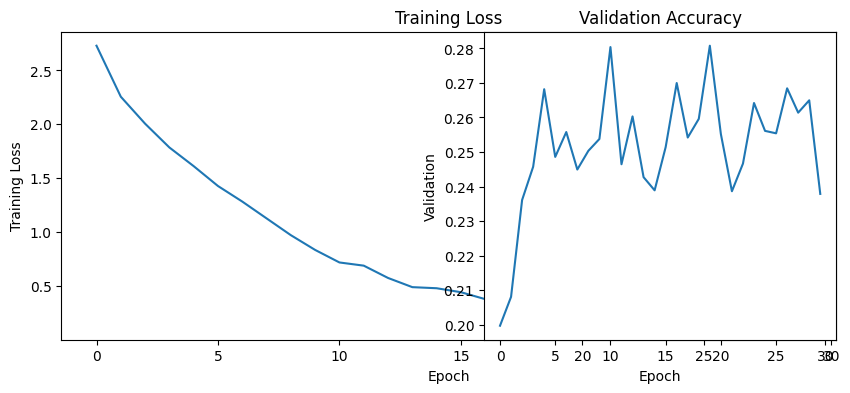

In [ ]:
# TODO A3: 32x32 RGB input, one hidden layer of 256 units, ReLU, 19 outputs. Suggested: AdamW, batch 64, 30 epochs,
# lr 1e-3, weight decay 1e-4. Record training loss and validation accuracy per epoch for the curves.
# Functions: nn.Module; nn.Sequential; nn.Linear; nn.ReLU; x.flatten(1)
class A3(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3072, 256),
            nn.ReLU(),
            nn.Linear(256, 19)
        )

    def forward(self, x):
        return self.net(x.flatten(1))


x_train = torch.from_numpy(X32_std[idx_train]).permute(0, 3, 1, 2).float().to(DEV)
y_train = torch.from_numpy(y[idx_train]).long().to(DEV)
x_val = torch.from_numpy(X32_std[idx_val]).permute(0, 3, 1, 2).float().to(DEV)
y_val = torch.from_numpy(y[idx_val]).long().to(DEV)


model = A3().to(DEV)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
batch_size = 64
epochs = 30
train_losses = []
val_accuracies = []

n = len(x_train)
for epoch in range(epochs):
    model.train()
    rng = np.random.default_rng(epoch).permutation(n)
    losses = []

    for i in range(0, n, batch_size):
        b = rng[i:i+batch_size]

        logits = model(x_train[b])
        loss = F.cross_entropy(logits, y_train[b])

        opt.zero_grad()
        loss.backward()
        opt.step()

        losses.append(loss.item())

    train_losses.append(np.mean(losses))

    model.eval()
    with torch.no_grad():
        pred = model(x_val).argmax(1)
        val_acc = mean_class_acc(pred, y_val, range(19))

    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}: Loss = {train_losses[-1]:.4f}, "
          f"Validation Accuracy = {val_acc:.4f}")


plt.figure(figsize=(10, 4))
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies)
plt.xlabel("Epoch")
plt.ylabel("Validation")
plt.title("Validation Accuracy")
plt.show()
torch.save(model.state_dict(), os.path.join(CKPT_DIR, "a3.pt"))

## A4: CNN from scratch

Write your milestone predictions for A4, A5, A6-H, and A6-L **before** you train any of them. Then run the overfit check before the full A4 run.

In [ ]:
# TODO Overfit check: a fresh A4, 150 updates on one batch of 64 training crops, no flips, AdamW lr 1e-3. Accuracy on
# those same 64 crops should exceed 0.9; if it does not, look for a bug in the data, the model, or the loop first.
# A4: CNN from scratch - Overfit check

# Basic residual block
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        out = F.relu(out)
        return out


# A4 model
class A4(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 7, stride=1, padding=3, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.stage1 = nn.Sequential(
            BasicBlock(32, 32),
            BasicBlock(32, 32)
        )

        self.stage2 = nn.Sequential(
            BasicBlock(32, 64, stride=2),
            BasicBlock(64, 64)
        )

        self.stage3 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )

        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = x.mean(dim=(2, 3))
        x = self.fc(x)
        return x


# Prepare one batch of 64 training crops
x_batch = torch.from_numpy(X64[idx_train[:64]]).permute(0, 3, 1, 2).float().to(DEV) / 255.0
y_batch = torch.from_numpy(y[idx_train[:64]]).long().to(DEV)

# Fresh A4 model
model = A4().to(DEV)

opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

# Train on the same 64 images for 150 updates
for step in range(150):
    model.train()

    logits = model(x_batch)
    loss = F.cross_entropy(logits, y_batch)

    opt.zero_grad()
    loss.backward()
    opt.step()

model.eval()

with torch.no_grad():
    pred = model(x_batch).argmax(1)
    accuracy = (pred == y_batch).float().mean().item()

print("Overfit check accuracy:", accuracy)

Overfit check accuracy: 1.0


In [ ]:
print("DEV:", DEV)
print("CUDA available:", torch.cuda.is_available())
print("Model device:", next(model.parameters()).device)
print("Input shape:", x_batch.shape)
print("Input device:", x_batch.device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEV: cuda
CUDA available: True
Model device: cuda:0
Input shape: torch.Size([64, 3, 64, 64])
Input device: cuda:0
GPU: Tesla T4


In [ ]:
# TODO A4: 64x64 input; required (report any change), a small ResNet: stem = 7x7 conv (32 channels, stride 1, padding 3), BN, ReLU;
# three residual stages of widths 32, 64, 128, two basic blocks each; global average pooling; linear output.
# Basic block: 3x3 conv (padding 1), BN, ReLU, 3x3 conv (padding 1), BN; add the shortcut; then ReLU. The first block of
# stages 2 and 3 uses stride 2 in its first conv and a projection shortcut (1x1 conv with stride 2, then BN); all other strides
# are 1 and all other shortcuts the identity.
# Functions: nn.Conv2d(cin, cout, k, stride, padding, bias=False); nn.BatchNorm2d; F.relu; x.mean(dim=(2, 3));
#    torch.rand; torch.where; x.flip(3); copy.deepcopy(model.state_dict())
# Prepare 64x64 training and validation data
x_train64 = torch.from_numpy(X64[idx_train]).permute(0, 3, 1, 2).float().to(DEV) / 255.0
y_train64 = torch.from_numpy(y[idx_train]).long().to(DEV)

x_val64 = torch.from_numpy(X64[idx_val]).permute(0, 3, 1, 2).float().to(DEV)
x_val64 = x_val64 / 255.0
y_val64 = torch.from_numpy(y[idx_val]).long().to(DEV)

model = A4().to(DEV)
# Before training, save a copy of the initial weights (copy.deepcopy(model.state_dict())) to CKPT_DIR: V4(a) needs them.
import copy
torch.save(
    copy.deepcopy(model.state_dict()),
    os.path.join(CKPT_DIR, "a4_initial.pt")
)

opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

epochs = 20
batch_size = 64
best_val_acc = -1

for epoch in range(epochs):
    model.train()
    perm = torch.randperm(len(x_train64), device=DEV)
    losses = []

    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        xb = x_train64[b]
        yb = y_train64[b]

        # Horizontal flips (p = 0.5), nothing else. Keep the checkpoint with the best validation accuracy.
        flip = torch.rand(len(xb), device=DEV) < 0.5
        xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)

        logits = model(xb)
        loss = F.cross_entropy(logits, yb)

        opt.zero_grad()
        loss.backward()
        opt.step()

        losses.append(loss.item())

    # Validation
    model.eval()
    with torch.no_grad():
        pred = model(x_val64).argmax(1)
        val_acc = mean_class_acc(pred, y_val64, range(19))

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {np.mean(losses):.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

    # Save the best validation checkpoint
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            model.state_dict(),
            os.path.join(CKPT_DIR, "a4.pt")
        )

print("Best A4 validation accuracy:", best_val_acc)

Epoch 1: Loss = 2.4993, Validation Accuracy = 0.0970
Epoch 2: Loss = 2.2788, Validation Accuracy = 0.1506
Epoch 3: Loss = 2.0870, Validation Accuracy = 0.1987
Epoch 4: Loss = 1.9251, Validation Accuracy = 0.2937
Epoch 5: Loss = 1.8060, Validation Accuracy = 0.3178
Epoch 6: Loss = 1.6845, Validation Accuracy = 0.4061
Epoch 7: Loss = 1.5807, Validation Accuracy = 0.3845
Epoch 8: Loss = 1.4919, Validation Accuracy = 0.4044
Epoch 9: Loss = 1.4216, Validation Accuracy = 0.4021
Epoch 10: Loss = 1.3412, Validation Accuracy = 0.4854
Epoch 11: Loss = 1.2697, Validation Accuracy = 0.3832
Epoch 12: Loss = 1.2202, Validation Accuracy = 0.4972
Epoch 13: Loss = 1.1524, Validation Accuracy = 0.5345
Epoch 14: Loss = 1.1302, Validation Accuracy = 0.5510
Epoch 15: Loss = 1.0662, Validation Accuracy = 0.4620
Epoch 16: Loss = 0.9954, Validation Accuracy = 0.4360
Epoch 17: Loss = 0.9512, Validation Accuracy = 0.5111
Epoch 18: Loss = 0.9062, Validation Accuracy = 0.4752
Epoch 19: Loss = 0.8620, Validation A

## A5: ViT from scratch

In [ ]:
# TODO A5: 64x64 input; required (report any change): 8x8 patches embedded by an 8x8 conv with stride 8 (64 tokens of
# width 128), a learned class token, learned position embeddings, 4 pre-norm blocks (4 heads, MLP ratio 4 = hidden width 512,
# GELU, no dropout), a final
# LayerNorm, and a linear output on the class token. With nn.TransformerEncoderLayer set norm_first=True, activation='gelu',
# dropout=0.0, batch_first=True: its defaults differ. Same input and augmentation as A4; lr 3e-4, weight decay 1e-2.
#    nn.TransformerEncoder(layer, 4, enable_nested_tensor=False); nn.LayerNorm(128); torch.cat
class A5(nn.Module):
    def __init__(self):
        super().__init__()

        # 8x8 patches -> 128-dimensional tokens
        self.patch_embed = nn.Conv2d(3, 128, kernel_size=8, stride=8)

        #a learned class token, learned position embeddings, 4 pre-norm blocks (4 heads, MLP ratio 4 = hidden width 512,
        # GELU, no dropout), a final
        self.cls_token = nn.Parameter(torch.zeros(1, 1, 128))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, 128))

        # With nn.TransformerEncoderLayer set norm_first=True, activation='gelu',
        # nn.TransformerEncoderLayer(128, 4, 512, dropout=0.0, activation='gelu', batch_first=True, norm_first=True);
        layer = nn.TransformerEncoderLayer(
            128,
            4,
            512,
            dropout=0.0,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            layer, 4, enable_nested_tensor=False
        )

        self.norm = nn.LayerNorm(128)
        self.fc = nn.Linear(128, 19)

    def forward(self, x):
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)

        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat([cls, x], dim=1)

        x = x + self.pos_embed
        x = self.transformer(x)

        x = self.norm(x[:, 0])
        x = self.fc(x)

        return x

In [ ]:
# Functions: nn.Conv2d(3, 128, 8, 8); nn.Parameter(torch.zeros(1, 1, 128));
model_a5 = A5().to(DEV)

opt = torch.optim.AdamW(
    model_a5.parameters(),
    lr=3e-4,
    weight_decay=1e-2
)

epochs = 20
batch_size = 64
best_val_acc_a5 = -1

for epoch in range(epochs):
    model_a5.train()
    perm = torch.randperm(len(x_train64), device=DEV)
    losses = []

    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        xb = x_train64[b]
        yb = y_train64[b]

        # Horizontal flip with p = 0.5
        flip = torch.rand(len(xb), device=DEV) < 0.5
        xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)

        logits = model_a5(xb)
        loss = F.cross_entropy(logits, yb)

        opt.zero_grad()
        loss.backward()
        opt.step()

        losses.append(loss.item())

    model_a5.eval()
    with torch.no_grad():
        pred = model_a5(x_val64).argmax(1)
        val_acc = mean_class_acc(pred, y_val64, range(19))

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {np.mean(losses):.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

    if val_acc > best_val_acc_a5:
        best_val_acc_a5 = val_acc
        torch.save(
            model_a5.state_dict(),
            os.path.join(CKPT_DIR, "a5.pt")
        )

print("Best A5 validation accuracy:", best_val_acc_a5)

Epoch 1: Loss = 2.7773, Validation Accuracy = 0.1230
Epoch 2: Loss = 2.5836, Validation Accuracy = 0.1425
Epoch 3: Loss = 2.4167, Validation Accuracy = 0.2076
Epoch 4: Loss = 2.2984, Validation Accuracy = 0.2109
Epoch 5: Loss = 2.1718, Validation Accuracy = 0.2336
Epoch 6: Loss = 2.0936, Validation Accuracy = 0.2777
Epoch 7: Loss = 1.9984, Validation Accuracy = 0.2929
Epoch 8: Loss = 1.9255, Validation Accuracy = 0.2833
Epoch 9: Loss = 1.8909, Validation Accuracy = 0.3006
Epoch 10: Loss = 1.8167, Validation Accuracy = 0.2831
Epoch 11: Loss = 1.7742, Validation Accuracy = 0.3184
Epoch 12: Loss = 1.7163, Validation Accuracy = 0.3195
Epoch 13: Loss = 1.6699, Validation Accuracy = 0.3399
Epoch 14: Loss = 1.6115, Validation Accuracy = 0.3217
Epoch 15: Loss = 1.5682, Validation Accuracy = 0.3059
Epoch 16: Loss = 1.5139, Validation Accuracy = 0.3355
Epoch 17: Loss = 1.4492, Validation Accuracy = 0.3324
Epoch 18: Loss = 1.3946, Validation Accuracy = 0.3365
Epoch 19: Loss = 1.3192, Validation A

In [ ]:
# Report the parameter counts of A4 and A5.
a4_params = sum(p.numel() for p in A4().parameters())
a5_params = sum(p.numel() for p in A5().parameters())

print("A4 parameters:", a4_params)
print("A5 parameters:", a5_params)

A4 parameters: 701619
A5 parameters: 828947


## A6: pretrained ViT-T/16, fine-tuned twice (A6-H and A6-L)

In [ ]:
# X224, _, _, _ = load_crops(224)     # 2.5 GB in memory; same order as X64, so the same split indices work
# Keep X224 as uint8 and convert one batch at a time: all of it as float32 is 10 GB, more than Colab's free RAM.

X224, _, _, _ = load_crops(224)

print("X224:", X224.shape)
print("X64:", X64.shape)
print("Device:", DEV)


X224: (16719, 224, 224, 3)
X64: (16719, 64, 64, 3)
Device: cuda


In [ ]:
# TODO A6: timm checkpoint vit_tiny_patch16_224.augreg_in21k_ft_in1k (ViT-Tiny: 12 pre-norm blocks of width 192,
# 3 heads, 16x16 patches). Replace its 1000-class head with a new 19-way linear layer, created right after torch.manual_seed(1);
# fine-tune everything.
# A6-H on the 224 px crops; A6-L on the 64 px crops upsampled to 224. Both start from the same original checkpoint.
# Use the checkpoint's normalization. Suggested: batch 32, 5 epochs, lr 1e-5 encoder and 1e-3 head, weight decay 1e-2,
# flips. Save both to CKPT_DIR: A6-H is used again in P1_V, P1_B and P1_665. Put its preprocessing (resize to 224 and the
# checkpoint's mean and std, model.pretrained_cfg) in my_models.py so those notebooks reuse it.
# Functions: timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k', pretrained=True);
#    torch.manual_seed(1); model.head = nn.Linear(192, 19); model.pretrained_cfg['mean'];
#    model.pretrained_cfg['std']; model.named_parameters(); torch.optim.AdamW([{'params': ..., 'lr': ...}, ...]);
#    F.interpolate(x, size=(224, 224), mode='bilinear') (A6-L)


import timm
import time

def train_a6(name, images, low=False):
    torch.manual_seed(0)
    rng = np.random.default_rng(0)

    model = timm.create_model(
        "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
        pretrained=True
    )

    torch.manual_seed(1)
    model.head = nn.Linear(192, 19)
    model = model.to(DEV)

    mean = torch.tensor(model.pretrained_cfg["mean"], device=DEV).view(1, 3, 1, 1)
    std = torch.tensor(model.pretrained_cfg["std"], device=DEV).view(1, 3, 1, 1)

    encoder = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    head = list(model.head.parameters())

    opt = torch.optim.AdamW([
        {"params": encoder, "lr": 1e-5},
        {"params": head, "lr": 1e-3}
    ], weight_decay=1e-2)

    best_acc = -1
    losses = []
    accuracies = []
    start = time.time()

    for epoch in range(5):
        model.train()
        order = rng.permutation(idx_train)
        total_loss = 0

        for i in range(0, len(order), 32):
            b = order[i:i+32]

            x = torch.from_numpy(images[b]).permute(0, 3, 1, 2).float().to(DEV) / 255.0
            labels = torch.as_tensor(y[b], dtype=torch.long, device=DEV)

            if low:
                x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)

            flip = torch.rand(len(x), device=DEV) < 0.5
            x[flip] = x[flip].flip(3)
            x = (x - mean) / std

            opt.zero_grad()
            loss = F.cross_entropy(model(x), labels)
            loss.backward()
            opt.step()

            total_loss += loss.item() * len(b)

        losses.append(total_loss / len(idx_train))

        model.eval()
        preds = []

        with torch.no_grad():
            for i in range(0, len(idx_val), 32):
                b = idx_val[i:i+32]
                x = torch.from_numpy(images[b]).permute(0, 3, 1, 2).float().to(DEV) / 255.0

                if low:
                    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)

                x = (x - mean) / std
                preds.append(model(x).argmax(1).cpu())

        pred = torch.cat(preds)
        labels = torch.as_tensor(y[idx_val])
        acc = mean_class_acc(pred, labels, range(19))
        accuracies.append(acc)

        print(f"{name} Epoch {epoch+1}/5: Loss = {losses[-1]:.4f}, Validation = {acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            torch.save(model.state_dict(), os.path.join(CKPT_DIR, name + ".pt"))

    elapsed = time.time() - start
    print(f"{name} Best validation: {best_acc:.4f}")
    print(f"{name} Training time: {elapsed:.1f} seconds")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return losses, accuracies, elapsed

a6h_loss, a6h_val, a6h_time = train_a6("a6_h", X224)
a6l_loss, a6l_val, a6l_time = train_a6("a6_l", X64, low=True)


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

a6_h Epoch 1/5: Loss = 0.7931, Validation = 0.8936
a6_h Epoch 2/5: Loss = 0.1935, Validation = 0.9034
a6_h Epoch 3/5: Loss = 0.0989, Validation = 0.9100
a6_h Epoch 4/5: Loss = 0.0518, Validation = 0.9143
a6_h Epoch 5/5: Loss = 0.0272, Validation = 0.9223
a6_h Best validation: 0.9223
a6_h Training time: 165.8 seconds
a6_l Epoch 1/5: Loss = 0.8544, Validation = 0.8703
a6_l Epoch 2/5: Loss = 0.2333, Validation = 0.8948
a6_l Epoch 3/5: Loss = 0.1232, Validation = 0.8966
a6_l Epoch 4/5: Loss = 0.0620, Validation = 0.9006
a6_l Epoch 5/5: Loss = 0.0305, Validation = 0.9051
a6_l Best validation: 0.9051
a6_l Training time: 162.1 seconds


## Table 1 and learning curves

,model,mean_acc_19,sofa,bottle,chair,diningtable,bus,input,params,train_data,train_time_s,hardware
0,A2-hsv,0.144990,0.007018,0.012953,0.518756,0.003436,0.000000,64x64 crop -> features,931,VOC train crops,5.3,T4
1,A2-hog,0.392923,0.196491,0.383420,0.460201,0.395189,0.483871,64x64 crop -> features,33535,VOC train crops,5.2,T4
2,A2-gabor,0.203535,0.000000,0.000000,0.661482,0.000000,0.186380,64x64 crop -> features,323,VOC train crops,5.5,T4
3,A2-all,0.437494,0.221053,0.393782,0.509607,0.453608,0.512545,64x64 crop -> features,34751,VOC train crops,5.2,T4
4,A1,0.170627,0.077193,0.051813,0.512351,0.000000,0.093190,32x32 RGB pixels,58387,VOC train crops,NaN,T4


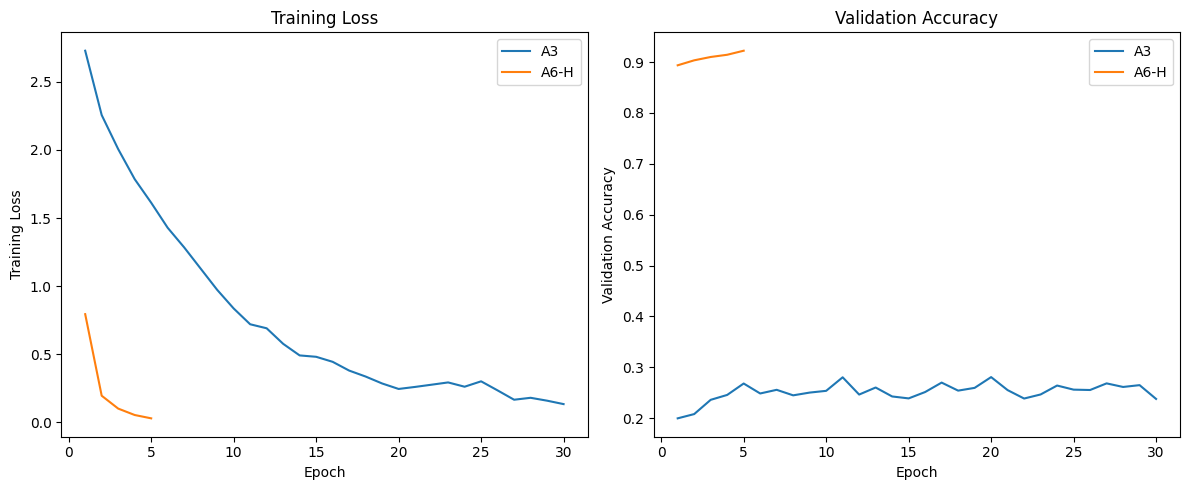

Table and plots saved in: /content/drive/MyDrive/p1/results


In [ ]:
# TODO Table 1 (e.g. a pandas DataFrame from TABLE1, saved to RESULTS_DIR), and the training-loss and
# validation-accuracy curves of A3, A4, A5 and A6-H. Copy your milestone predictions next to the results in your report.
# Functions: sum(p.numel() for p in model.parameters()); time.time(); pd.DataFrame(rows).to_csv(path); plt.plot

import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs(RESULTS_DIR, exist_ok=True)

df = pd.DataFrame(TABLE1)

columns = ["model", "mean_acc_19"] + list(MY_CLASSES)
columns += ["input", "params", "train_data", "train_time_s", "hardware"]

for col in columns:
    if col not in df.columns:
        df[col] = None

df = df[columns]
df.to_csv(os.path.join(RESULTS_DIR, "table1.csv"), index=False)

display(df)

histories = {
    "A3": (train_losses, val_accuracies),
    "A6-H": (a6h_loss, a6h_val)
}

if "a4_losses" in globals() and "a4_val" in globals():
    histories["A4"] = (a4_losses, a4_val)

if "a5_losses" in globals() and "a5_val" in globals():
    histories["A5"] = (a5_losses, a5_val)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

for name, (losses, accuracies) in histories.items():
    plt.plot(range(1, len(losses) + 1), losses, label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.legend()

plt.subplot(1, 2, 2)

for name, (losses, accuracies) in histories.items():
    plt.plot(range(1, len(accuracies) + 1), accuracies, label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "learning_curves.png"))
plt.show()

print("Table and plots saved in:", RESULTS_DIR)
